# Практическое занятие 2. Иркутск: кварталы и метрики города

**Территория:** Иркутск, Иркутская область, Россия
**Операционная система:** macOS
**BlocksNet:** 1.0.0a9

Ноутбук подготовлен с помощью OpenCode. Здесь рядом лежат код и его результаты (карты, таблицы).
Запускай ячейки по очереди кнопкой ▶ слева от ячейки. Перед запуском выбери ядро Python из окружения
проекта `.venv` (в VS Code: справа сверху «Select Kernel» → Python из `.venv`).

Данные и результаты сохраняются в папку `data/` в формате GeoJSON и переиспользуются при повторном
запуске: если файл уже есть, он просто читается и заново не скачивается.


## 0. Настройка

Импорты, папка для данных и вспомогательные функции сохранения/чтения GeoJSON.

In [1]:
from pathlib import Path

import time

import geopandas as gpd
import osmnx as ox
import pandas as pd

def find_project_root(start: Path) -> Path:
    """Идём вверх по папкам, пока не найдём корень проекта (pyproject.toml)."""
    start = start.resolve()
    for parent in [start, *start.parents]:
        if (parent / "pyproject.toml").exists():
            return parent
    return start


# Данные всегда в data/ в корне проекта — независимо от рабочей папки ядра.
PROJECT_ROOT = find_project_root(Path.cwd())
DATA = PROJECT_ROOT / "data"
DATA.mkdir(exist_ok=True)
print("Корень проекта:", PROJECT_ROOT)
print("Папка данных:", DATA)

TERRITORY = "Иркутск, Иркутская область, Россия"

# Настройки Overpass API: несколько зеркал и повторные попытки, чтобы пережить
# временную перегрузку сервера ("502 Bad Gateway").
OVERPASS_MIRRORS = [
    "https://overpass.kumi.systems/api",
    "https://overpass-api.de/api",
    "https://maps.mail.ru/osm/tools/overpass/api",
]
ox.settings.overpass_url = OVERPASS_MIRRORS[0]
ox.settings.overpass_rate_limit = True
ox.settings.requests_timeout = 300
# Кэш запросов OSM — тоже в корне проекта, чтобы не плодить папки.
ox.settings.use_cache = True
ox.settings.cache_folder = str(PROJECT_ROOT / "cache")


# Уличные дороги: именно они ограничивают кварталы. Пешеходные дорожки,
# тропы и лестницы сюда НЕ входят — иначе кварталы получаются слишком мелкими.
VEHICULAR_HIGHWAYS = [
    "construction", "living_street", "motorway", "motorway_link", "motorway_junction",
    "pedestrian", "primary", "primary_link", "residential", "road", "secondary",
    "secondary_link", "services", "tertiary", "tertiary_link", "track", "trunk",
    "trunk_link", "turning_circle", "turning_loop", "unclassified",
]


def load_geojson(name):
    path = DATA / name
    if path.exists():
        print("Читаю готовый файл:", path)
        return gpd.read_file(path)
    return None


def download_osm(name, tags, retries=8):
    """Скачать объекты OSM с кэшем, сменой зеркал и повторными попытками."""
    cached = load_geojson(name)
    if cached is not None:
        return cached
    for attempt in range(retries):
        ox.settings.overpass_url = OVERPASS_MIRRORS[attempt % len(OVERPASS_MIRRORS)]
        try:
            print(f"Скачиваю {name} (попытка {attempt + 1}, {ox.settings.overpass_url})...")
            gdf = ox.features_from_polygon(boundary_wgs.union_all(), tags)
            break
        except Exception as e:
            wait = 20 * (attempt + 1)
            print(f"  Не получилось ({type(e).__name__}). Жду {wait} с...")
            time.sleep(wait)
    else:
        raise RuntimeError(f"Не удалось скачать {name} после {retries} попыток")
    gdf = gdf.to_crs(crs)
    save_geojson(gdf, name)
    return gdf


def save_geojson(gdf, name):
    path = DATA / name
    gdf.to_file(path, driver="GeoJSON")
    print(f"Сохранил {path} ({len(gdf)} объектов)")



## Этап 1. Граница территории

Сначала получаем границу города по названию (источник — OpenStreetMap, через `osmnx.geocode_to_gdf`).
Граница нужна, чтобы скачивать данные только по нашей территории.

Система координат: подбираем подходящую проекцию (UTM) через `estimate_utm_crs`, чтобы длины и площади
считались в метрах, а не в градусах.

Читаю готовый файл: data/boundary.geojson
CRS: EPSG:32648


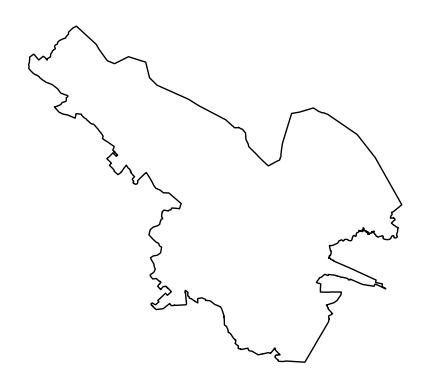

In [2]:
boundary = load_geojson("boundary.geojson")
if boundary is None:
    boundary = ox.geocode_to_gdf(TERRITORY)
    boundary = boundary.to_crs(boundary.estimate_utm_crs())
    save_geojson(boundary, "boundary.geojson")

crs = boundary.crs
print("CRS:", crs)
boundary.plot(color="none", edgecolor="black").set_axis_off()

## Этап 2. Данные OpenStreetMap: дороги, железные дороги, вода

Скачиваем объекты, по которым будем резать кварталы. Набор тегов такой же, как в примере BlocksNet
(`examples/pipeline.ipynb`). Источник: OpenStreetMap. Меняя теги, можно уточнить, что считать границей квартала.

In [3]:
import time

bc_tags = {
    # Все дороги OpenStreetMap (тег highway). Облегчённый запрос — так надёжнее
    # на публичных серверах Overpass API.
    "roads": {"highway": True},
    "railways": {"railway": "rail"},
    "water": {
        "riverbank": True,
        "reservoir": True,
        "basin": True,
        "dock": True,
        "canal": True,
        "pond": True,
        "natural": ["water", "bay"],
        "waterway": ["river", "canal", "ditch"],
        "landuse": "basin",
        "water": "lake",
    },
}

boundary_wgs = boundary.to_crs(4326)


def fetch_osm(name, tags, geom_types, retries=8):
    cached = load_geojson(name)
    if cached is not None:
        return cached
    for attempt in range(retries):
        ox.settings.overpass_url = OVERPASS_MIRRORS[attempt % len(OVERPASS_MIRRORS)]
        try:
            print(f"Скачиваю {name} (попытка {attempt + 1}, сервер {ox.settings.overpass_url})...")
            gdf = ox.features_from_polygon(boundary_wgs.union_all(), tags)
            break
        except Exception as e:
            wait = 20 * (attempt + 1)
            print(f"  Не получилось ({type(e).__name__}). Жду {wait} с и пробую снова...")
            time.sleep(wait)
    else:
        raise RuntimeError(f"Не удалось скачать {name} после {retries} попыток")
    gdf = gdf[gdf.geom_type.isin(geom_types)].reset_index(drop=True)
    gdf = gdf.to_crs(crs)
    save_geojson(gdf, name)
    return gdf


water = fetch_osm("water.geojson", bc_tags["water"], ["Polygon", "MultiPolygon", "LineString", "MultiLineString"])
roads = fetch_osm("roads.geojson", bc_tags["roads"], ["LineString", "MultiLineString"])
# Оставляем только уличные дороги и перезаписываем файл — так кварталы не мельчат.
roads = roads[roads["highway"].isin(VEHICULAR_HIGHWAYS)].reset_index(drop=True)
save_geojson(roads, "roads.geojson")
railways = fetch_osm("railways.geojson", bc_tags["railways"], ["LineString", "MultiLineString"])


Читаю готовый файл: data/water.geojson
Читаю готовый файл: data/roads.geojson


Сохранил data/roads.geojson (4498 объектов)
Читаю готовый файл: data/railways.geojson


## Этап 3. Нарезка кварталов

`preprocess_urban_objects` приводит геометрии к единому виду (линии и полигоны), затем
`cut_urban_blocks` режет территорию по дорогам, железным дорогам и воде и получает кварталы —
замкнутые участки между улицами, без водных объектов.

/Users/ekaterina/03_Учеба/ИТМО/ИИ в урбанистике/python-package-boilerplate/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Читаю готовый файл: data/blocks.geojson
Кварталов: 2677


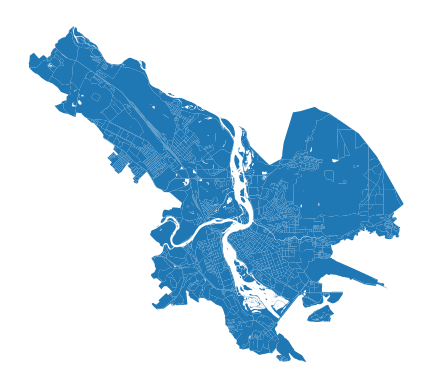

In [4]:
from blocksnet.blocks.cutting import cut_urban_blocks, preprocess_urban_objects

blocks = load_geojson("blocks.geojson")
if blocks is None:
    lines, polygons = preprocess_urban_objects(roads, railways, water)
    blocks = cut_urban_blocks(boundary, lines, polygons)
    save_geojson(blocks, "blocks.geojson")

print("Кварталов:", len(blocks))
blocks.plot().set_axis_off()

---
## ⛔ ОСТАНОВКА после подготовки кварталов

Выполни ячейки **до этого места**. Посмотри на карту границы и кварталов выше.

Проверь:
- это действительно Иркутск, граница охватывает нужный район?
- нет ли явно лишних участков или пропущенной части?

Если заметила проблему — опиши её обычными словами, и мы исправим границы до расчётов.
Перед расчётами **спроси у агента о метриках** (какие показатели есть в BlocksNet).

Ячейки ниже пока **не запускай**.
---

## Что означают метрики BlocksNet

Ниже — все показатели из примера BlocksNet (`examples/pipeline.ipynb`), сгруппированные по смыслу.
Для каждого указано: что он значит простыми словами, в каких единицах измеряется и какие данные нужны
для расчёта. Значения, которые библиотека **восстанавливает** по допущениям, помечены словом **(оценка)**.

### 1. Землепользование (land use) — функция `assign_land_use`

| Показатель | Что означает | Единицы | Нужные данные |
| --- | --- | --- | --- |
| `residential`, `business`, `recreation`, `industrial`, `transport`, `special`, `agriculture` | Доля площади квартала под каждой функцией: жильё, бизнес, рекреация, промышленность, транспорт, спец. объекты, сельское хозяйство | доля 0–1 (без единиц) | кварталы + полигоны функциональных зон OSM (тег `landuse`) + правила перевода тегов OSM в группы BlocksNet |
| `land_use` | Преобладающая функция квартала | категория | то же |
| `share` | Доля площади, которую занимает преобладающая функция | доля 0–1 | то же |

### 2. Время в пути (матрица доступности) — `calculate_accessibility_matrix`

| Показатель | Что означает | Единицы | Нужные данные |
| --- | --- | --- | --- |
| `acc_mx` | Время в пути по кратчайшему маршруту между центрами каждой пары кварталов. Матрица `n×n` | минуты | кварталы + граф города; вес ребра графа — время, мин |

Граф бывает трёх видов: `walk` (пешеходный), `drive` (автомобильный) и `intermodal` (пешком + транспорт);
в примере строится **интермодальный**. Вместо матрицы доступности бывают ещё матрица расстояний (метры)
и граф смежности кварталов (кто с кем граничит).

### 3. Здания и население — `aggregate_objects`, `impute_buildings`

Сначала характеристики считаются для каждого здания, потом суммируются внутри квартала.

| Показатель | Что означает | Единицы | Нужные данные |
| --- | --- | --- | --- |
| `footprint_area` | Площадь застройки здания (контур на земле) | м² | контуры зданий из OSM |
| `number_of_floors` | Число этажей | этажей | тег `building:levels`; если нет — подставляется значение по умолчанию (оценка) |
| `build_floor_area` | Суммарная площадь всех этажей = этажность × площадь застройки | м² | считается из двух предыдущих (оценка, если этажность неизвестна) |
| `is_living` | Жилое ли здание | да / нет | тег `building` (список жилых типов) |
| `living_area` | Жилая площадь | м² | доля 0,9 от площади этажей для жилых (оценка) |
| `non_living_area` | Нежилая площадь | м² | площадь этажей минус жилая (оценка) |
| `population` | Численность жителей здания, затем сумма по кварталу | человек (оценка) | жилая площадь ÷ норма площади на человека (оценка) |
| `count` | Число зданий в квартале | шт. | считается автоматически |

### 4. Школы — `impute_services`, `aggregate_objects`

| Показатель | Что означает | Единицы | Нужные данные |
| --- | --- | --- | --- |
| `capacity` | Вместимость школ квартала (сколько учеников вмещают) | мест | объекты `amenity=school`; если вместимость не указана — подставляется минимум из настроек (оценка) |
| `count` | Число школ в квартале | шт. | считается автоматически |

### 5. Обеспеченность школами — `competitive_provision`

| Показатель | Что означает | Единицы | Нужные данные |
| --- | --- | --- | --- |
| `demand` | Потребность квартала в школьных местах | мест | население × норму (120 мест на 1000 жителей) (оценка) |
| `provision_strong` | Доля потребности, закрытая местами **в пределах порога доступности** (оценка, 0–1) | доля 0–1 | `demand`, `capacity`, матрица доступности |
| `provision_weak` | Доля потребности, закрытая доступными местами **в любом удалённом** квартале | доля 0–1 | то же |
| `demand_within`, `demand_without` | Потребность, закрытая в пределах порога / за порогом | мест | то же |
| `demand_left` | Непокрытая потребность | мест | то же |
| `capacity_within`, `capacity_without`, `capacity_left` | Места, использованные в пределах порога / за порогом / свободные | мест | то же |
| `links` (`source`, `target`, `value`) | Сколько мест из квартала-школы получает конкретный квартал-потребитель | мест | то же |

Порог доступности и норму задаёт конфигурация BlocksNet для школ: **15 минут** и **120 мест на 1000 жителей**.

### 6. Плотность застройки — `calculate_density_indicators`

| Показатель | Что означает | Единицы | Нужные данные |
| --- | --- | --- | --- |
| `fsi` | Интенсивность застройки: сколько площади этажей приходится на площадь участка | безразмерный | агрегированные здания + площадь квартала |
| `gsi` | Доля участка, занятая застройкой | доля 0–1 | контуры зданий + площадь квартала |
| `mxi` | Доля жилой площади во всей площади этажей | доля 0–1 | жилая и общая площадь этажей |
| `l` | Средняя этажность застройки | этажей | площадь этажей ÷ площадь застройки |
| `osr` | Открытые пространства на единицу площади этажей | безразмерный | площадь квартала и застройки |
| `share_living`, `share_non_living` | Доля жилой / нежилой площади | доля 0–1 | жилая, нежилая площадь, застройка |

### 7. Типы застройки (морфотипы) — `get_spacematrix_morphotypes`, `get_strelka_morphotypes`

| Показатель | Что означает | Единицы | Нужные данные |
| --- | --- | --- | --- |
| Spacematrix `cluster` | Номер группы квартала, выделенной методом кластеризации (11 групп) | номер 0–10 | `l`, `fsi`, `mxi` |
| Spacematrix `morphotype` | Текстовое описание группы: этажность + плотность + доля жилья (например «mid-rise high-density mixed-use») | категория | то же |
| «Стрелка» `morphotype` | Тип квартала по правилам (низко-, средне-, высокоэтажные и их подтипы) | категория | `l`, `fsi`, `mxi` |

### 8. Доступность с учётом площади — `area_accessibility`

| Показатель | Что означает | Единицы | Нужные данные |
| --- | --- | --- | --- |
| `area_accessibility` | Средневзвешенное по площади время в пути от квартала ко всем остальным. Чем меньше — тем ближе квартал к городу | минуты | матрица доступности + площадь кварталов |

### Общие допущения и источники

- Все пространственные данные — **OpenStreetMap**; границы кварталов строятся по дорогам, железным дорогам и воде.
- Показатели, помеченные «(оценка)», BlocksNet вычисляет по формулам, а не берёт из статистики: население, вместимость части школ, доли площадей. Их нельзя сравнивать с официальной статистикой напрямую.
- Норма площади на человека и вместимость школ по умолчанию задаются в настройках BlocksNet; при другом выборе значений результаты изменятся.
- Расчёты ниже ещё **не выполнены** — это описание показателей; код расчёта идёт в следующих ячейках.


# ───────── ДАЛЬШЕ — РАСЧЁТЫ ─────────

## Этап 4. Землепользование (land use)

Каждому кварталу присваиваем доли разных функций (жильё, бизнес, рекреация, промышленность и т.д.)
по данным OSM (`landuse`) и правило перевода тегов OSM в группы BlocksNet. В результате у квартала
появляется преобладающая функция (`land_use`) и её доля (`share`).

Читаю готовый файл: data/functional_zones_raw.geojson


2026-10-17 10:43:51.916 | WARNING  | blocksnet.blocks.assignment.land_use:_preprocess_functional_zones:17 - Functional zones not in rules: reservoir, farmyard, institutional, greenfield, culture, allotments, plant_nursery, aquaculture, railway, basin


Сохранил data/functional_zones.geojson (2002 объектов)


Сохранил data/blocks.geojson (2677 объектов)


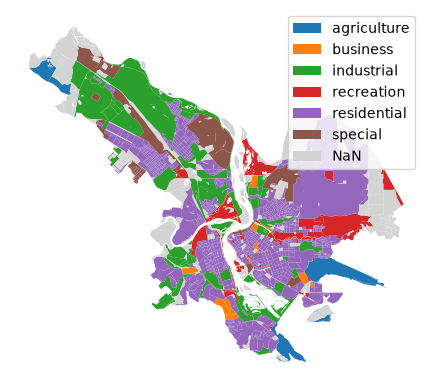

In [5]:
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.enums import LandUse

functional_zones = download_osm("functional_zones_raw.geojson", {"landuse": True})
functional_zones = (
    functional_zones.reset_index(drop=True)[["geometry", "landuse"]]
    .rename(columns={"landuse": "functional_zone"})
    .to_crs(crs)
)
save_geojson(functional_zones, "functional_zones.geojson")

rules = {
    "commercial": LandUse.BUSINESS,
    "retail": LandUse.BUSINESS,
    "industrial": LandUse.INDUSTRIAL,
    "garages": LandUse.INDUSTRIAL,
    "brownfield": LandUse.INDUSTRIAL,
    "cemetery": LandUse.SPECIAL,
    "religious": LandUse.SPECIAL,
    "construction": LandUse.SPECIAL,
    "military": LandUse.SPECIAL,
    "residential": LandUse.RESIDENTIAL,
    "grass": LandUse.RECREATION,
    "forest": LandUse.RECREATION,
    "recreation_ground": LandUse.RECREATION,
    "flowerbed": LandUse.RECREATION,
    "farmland": LandUse.AGRICULTURE,
    "landfill": LandUse.TRANSPORT,
}

blocks = assign_land_use(blocks, functional_zones, rules)
# land_use — это enum; переводим в обычную строку, иначе карта не строит легенду.
blocks["land_use"] = blocks["land_use"].apply(lambda x: x.value if hasattr(x, "value") else x)
save_geojson(blocks, "blocks.geojson")
blocks.plot(column="land_use", legend=True, missing_kwds={"color": "lightgrey"}).set_axis_off()


### Результат этапа 4: доли функций и преобладающая функция

`assign_land_use` добавляет к каждому кварталу показатели землепользования:

| Показатель | Что означает | Единицы |
| --- | --- | --- |
| `residential`, `business`, `recreation`, `industrial`, `transport`, `special`, `agriculture` | доля площади квартала под каждой функцией | 0–1 |
| `land_use` | преобладающая функция квартала | категория |
| `share` | доля площади у преобладающей функции | 0–1 |

Сумма семи долей ≤ 1: часть квартала может не попадать ни в одну зону `landuse`.
Если у квартала нет функциональных зон, `land_use` пустой, а `share` = NaN — это **отсутствие данных**, а не ноль.

Землепользование берётся из OSM (тег `landuse`), это не модельная оценка, но результат зависит от того,
насколько подробно размечены зоны в OSM.

Результат сохраняется в `data/blocks.geojson` (все доли и преобладающая функция) и в отдельный файл
`data/land_use.geojson`.


In [ ]:
# Все показатели землепользования из pipeline.ipynb: семь долей + преобладающая функция + её доля.
LU_COLUMNS = ["residential", "business", "recreation", "industrial",
              "transport", "special", "agriculture"]

rows = []
for col in LU_COLUMNS:
    rows.append({
        "Функция": col,
        "Кварталов с этой функцией": int((blocks[col] > 0).sum()),
        "Кварталов, где преобладает": int((blocks["land_use"] == col).sum()),
        "Средняя доля (0–1)": round(blocks[col].mean(), 3),
    })
lu_summary = pd.DataFrame(rows).set_index("Функция")

no_zone = int(blocks["land_use"].isna().sum())
print("Кварталов без данных о функции (нет зон landuse):", no_zone, "из", len(blocks))
lu_summary


In [ ]:
# Пример: доля каждой функции и преобладающая функция у первых кварталов.
preview = blocks[["land_use", "share"] + LU_COLUMNS].copy()
preview["share"] = preview["share"].round(3)
preview[LU_COLUMNS] = preview[LU_COLUMNS].round(3)
preview.head(15)


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

blocks["land_use"].fillna("нет данных").value_counts().plot(
    kind="bar", ax=axes[0], color="#4C72B0"
)
axes[0].set_title("Кварталы по преобладающей функции")
axes[0].set_xlabel("Преобладающая функция")
axes[0].set_ylabel("Число кварталов")
axes[0].tick_params(axis="x", rotation=45)

block_area = blocks.geometry.area
area_share = {col: float(block_area[blocks[col] > 0].sum() / block_area.sum()) for col in LU_COLUMNS}
pd.Series(area_share).sort_values().plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("Доля площади города под каждой функцией")
axes[1].set_xlabel("Доля площади (0–1)")

plt.tight_layout()
plt.show()


In [ ]:
# Сохраняем результат этапа в GeoJSON: геометрия + все показатели землепользования.
land_use_layer = blocks[["land_use", "share"] + LU_COLUMNS + ["geometry"]].copy()
save_geojson(land_use_layer, "land_use.geojson")


## Этап 5. Время в пути между кварталами

**Выбранный граф: пешеходный (`"walk"`).** Интермодальный граф (пешком + общественный транспорт) не строим —
он тяжелее и дольше.

- **Источник графа:** данные OpenStreetMap; загрузка и сборка графа — библиотекой IduEdu
  (`get_walk_graph`), которую использует BlocksNet (`get_accessibility_graph(boundary, "walk")`).
- **Способ передвижения:** пешком.
- **Единицы результата:** минуты.

Граф кэшируется в `data/graph_walk.pkl` (формат pickle: обычный `.graphml` не умеет хранить геометрию рёбер),
поэтому повторный запуск не скачивает его заново.

`calculate_accessibility_matrix` считает время по кратчайшему маршруту между центрами всех кварталов.
Результат — квадратная таблица «квартал × квартал» в **минутах** (диагональ = 0).

Матрицу сохраняем в `data/accessibility_matrix.csv` (это таблица, а не география), а для карты и дальнейших
расчётов — сводку по кварталам в `data/travel_time.geojson`.


In [ ]:
import pickle
import time

import iduedu
from blocksnet.relations import get_accessibility_graph

# Выбранный готовый граф — пешеходный. Интермодальный не строим.
GRAPH_TYPE = "walk"

# Зеркала Overpass для сборки графа (IduEdu использует свой адрес).
IDUEDU_MIRRORS = [
    "https://overpass-api.de/api/interpreter",
    "https://overpass.kumi.systems/api/interpreter",
    "https://maps.mail.ru/osm/tools/overpass/api/interpreter",
]

graph_path = DATA / f"graph_{GRAPH_TYPE}.pkl"
if graph_path.exists():
    with open(graph_path, "rb") as f:
        graph = pickle.load(f)
    print("Читаю готовый граф:", graph_path)
else:
    graph = None
    for attempt in range(6):
        iduedu.config.set_overpass_url(IDUEDU_MIRRORS[attempt % len(IDUEDU_MIRRORS)])
        try:
            print(f"Собираю граф ({GRAPH_TYPE}) по Overpass: попытка {attempt + 1}, {iduedu.config.overpass_url}")
            graph = get_accessibility_graph(boundary, GRAPH_TYPE)
            break
        except Exception as e:
            wait = 20 * (attempt + 1)
            print(f"  Не получилось ({type(e).__name__}). Жду {wait} с...")
            time.sleep(wait)
    if graph is None:
        raise RuntimeError("Не удалось собрать граф после нескольких попыток. Проверь интернет и запусти ячейку снова.")
    with open(graph_path, "wb") as f:
        pickle.dump(graph, f)
    print("Сохранил граф:", graph_path)

print("Граф:", GRAPH_TYPE, "| способ передвижения: пешком | источник: OpenStreetMap (сборка IduEdu)")
print("Узлов:", graph.number_of_nodes(), "| рёбер:", graph.number_of_edges())


In [ ]:
from blocksnet.relations import calculate_accessibility_matrix

# Время в пути между кварталами по выбранному графу. Единицы — минуты.
acc_mx = calculate_accessibility_matrix(blocks, graph)
acc_mx.to_csv(DATA / "accessibility_matrix.csv")
print("Матрица времени в пути:", acc_mx.shape, "| единицы: минуты (диагональ = 0)")
acc_mx.head()


In [ ]:
import numpy as np

# Статистика по всем парам кварталов (диагональ 0 не учитываем).
mtx_vals = acc_mx.astype(float).to_numpy()
n = mtx_vals.shape[0]
mask = ~np.eye(n, dtype=bool)
pairs = mtx_vals[mask]
unreachable = int(np.isnan(pairs).sum())
known = pairs[~np.isnan(pairs)]

travel_stats = pd.Series({
    "минимум, мин": known.min(),
    "среднее, мин": known.mean(),
    "медиана, мин": np.median(known),
    "максимум, мин": known.max(),
}).round(2)

print("Пар кварталов:", pairs.shape[0], "| недостижимых (нет пути):", unreachable)
travel_stats


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Сводка для карты: среднее время в пути от квартала до всех остальных (минуты).
mtx = acc_mx.astype(float).copy()
np.fill_diagonal(mtx.values, np.nan)
travel_time = mtx.mean(axis=1).rename("travel_time_mean")
blocks_tt = blocks.join(travel_time)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

blocks_tt.plot(column="travel_time_mean", cmap="magma", legend=True,
               missing_kwds={"color": "lightgrey"}, ax=axes[0])
axes[0].set_title("Среднее время в пути до остальных кварталов, минуты")
axes[0].set_axis_off()

travel_time.plot(kind="hist", bins=30, color="#8172B2", ax=axes[1])
axes[1].set_title("Распределение времени в пути по кварталам")
axes[1].set_xlabel("Среднее время в пути, минуты")
axes[1].set_ylabel("Число кварталов")

plt.tight_layout()
plt.show()


In [ ]:
# Сохраняем сводку времени в пути по кварталам в GeoJSON.
travel_time_layer = blocks[["geometry"]].join(travel_time)
save_geojson(travel_time_layer, "travel_time.geojson")

# Проверка чтения для следующих расчётов (обеспеченность, доступность с учётом площади).
acc_check = pd.read_csv(DATA / "accessibility_matrix.csv", index_col=0)
with open(graph_path, "rb") as f:
    graph_check = pickle.load(f)
tt_check = load_geojson("travel_time.geojson")

print("Матрица прочитана:", acc_check.shape)
print("Число кварталов в матрице совпадает с blocks:",
      acc_check.shape[0] == len(blocks) and acc_check.shape[1] == len(blocks))
print("Граф прочитан: узлов", graph_check.number_of_nodes())
print("travel_time.geojson прочитан:", len(tt_check), "объектов")


## Этап 6. Здания и оценка населения

По примеру BlocksNet (раздел «Buildings aggregation») здание описывается набором показателей.
Часть из них берётся **из данных OpenStreetMap**, часть **рассчитывается моделью по допущениям**.

| Показатель | Единица | Источник | Как получен |
|---|---|---|---|
| `footprint_area` | м² | данные (геометрия OSM) | площадь контура здания |
| `number_of_floors` | этажей | данные / допущение | тег `building:levels`; если нет — допущение |
| `is_living` | да/нет | данные | по типу здания (тег `building`) |
| `build_floor_area` | м² | оценка | этажность × площадь застройки |
| `living_area` | м² | оценка | 0.9 × площадь этажей (для жилых) |
| `non_living_area` | м² | оценка | площадь этажей − жилая площадь |
| `population` | чел. | оценка | жилая площадь ÷ 30 м² на человека |
| `count` | шт. | расчёт | число зданий в квартале |

Итог этапа — показатели **по кварталам** в `buildings_blocks`, которые сохраняются в
`data/buildings_blocks.geojson` и используются дальше (плотность, обеспеченность, доступность).


### 6.1. Данные из OpenStreetMap (не оценка)

Скачиваем все здания по тегу `building` и формируем признаки прямо из тегов OSM:

- `is_living` — жилое здание или нет (по списку жилых типов);
- `number_of_floors` — этажность из тега `building:levels` (у части зданий тега нет — там будет пропуск);
- `footprint_area` — площадь застройки из геометрии здания (тоже данные, а не оценка).


In [ ]:
# Данные OSM: здания и их базовые характеристики.
buildings = download_osm("buildings_raw.geojson", {"building": True}).reset_index(drop=True)

# is_living — жилое ли здание (по типу здания).
is_living_tags = ["residential", "house", "apartments", "detached", "terrace", "dormitory"]
buildings["is_living"] = buildings["building"].apply(lambda b: b in is_living_tags)

# number_of_floors — этажность из тега building:levels (если тега нет — будет пропуск).
levels = buildings["building:levels"] if "building:levels" in buildings.columns else pd.Series(index=buildings.index, dtype=float)
buildings["number_of_floors"] = pd.to_numeric(levels, errors="coerce")

# footprint_area — площадь застройки из геометрии здания (данные OSM).
buildings["footprint_area"] = buildings.area

# Тип здания сохраняем отдельно: impute_buildings убирает исходные столбцы OSM.
building_types = buildings["building"].copy()

print("Зданий всего:", len(buildings))
print("Жилых (is_living):", int(buildings["is_living"].sum()))
print("Без этажности (нет building:levels):", int(buildings["number_of_floors"].isna().sum()),
      "| доля:", round(buildings["number_of_floors"].isna().mean(), 3))
buildings[["building", "is_living", "number_of_floors", "footprint_area"]].head()


### 6.2. Восстановление пропусков и производные показатели (оценки модели)

Функция `impute_buildings` заполняет пропуски и считает производные показатели **по допущениям**:

- `number_of_floors` = **1 этаж**, если в OSM тег отсутствует (допущение `default_number_of_floors`);
- `build_floor_area` = этажность × площадь застройки;
- `living_area` = 0.9 × площадь этажей, но только для жилых зданий (коэффициент `living_area_coefficient`);
- `non_living_area` = площадь этажей − жилая площадь;
- `population` = жилая площадь ÷ 30 м² на человека (норма `default_living_demand`), целое число, минимум 1.

Всё, что посчитано по этим формулам, — **модельная оценка**, а не факт из OSM.


In [ ]:
from blocksnet.preprocessing.imputing import impute_buildings

# impute_buildings восстанавливает пропуски и считает производные показатели.
# default_living_demand=30 — норма жилой площади на человека (30 м²/чел.); это ОЦЕНКА.
floors_missing_before = int(buildings["number_of_floors"].isna().sum())
buildings = impute_buildings(buildings, default_living_demand=30)
floors_missing_after = int(buildings["number_of_floors"].isna().sum())

print("Допущения модели: этажей по умолчанию = 1; жилая доля площади этажей = 0.9; норма = 30 м²/чел.")
print("Этажность: пропусков до", floors_missing_before, "→ после", floors_missing_after,
      "(заполнено допущением 1 этаж)")
print("Оценка населения города, чел.:", round(buildings["population"].sum()))
buildings[["footprint_area", "number_of_floors", "build_floor_area",
           "living_area", "non_living_area", "population"]].describe().round(1)


In [ ]:
# Пример по отдельным зданиям: видно, какие значения пришли из OSM, а какие — оценка модели.
# Тип здания берём из сохранённой копии: impute_buildings убирает исходные столбцы OSM.
idx = buildings.sample(8, random_state=42).index
sample = buildings.loc[idx, ["is_living", "number_of_floors", "footprint_area",
                             "build_floor_area", "living_area", "non_living_area", "population"]].copy()
sample.insert(0, "building", building_types.loc[idx])
sample.round(1)


### 6.3. Суммирование показателей по кварталам

`aggregate_objects` относит каждое здание к кварталу и **суммирует** числовые показатели:
`count` (число зданий), `footprint_area`, `number_of_floors`, `build_floor_area`,
`living_area`, `non_living_area`, `population`. Флаг `is_living` тоже суммируется, поэтому в таблице по кварталам это **число жилых зданий**.

Важно: `number_of_floors` в таблице — это **сумма этажей всех зданий квартала**, а не средняя этажность.


In [ ]:
from blocksnet.blocks.aggregation import aggregate_objects

# Суммируем характеристики зданий по кварталам; count — число зданий.
buildings_blocks = aggregate_objects(blocks, buildings)[0]
save_geojson(buildings_blocks, "buildings_blocks.geojson")

print("Кварталов со зданиями:", int((buildings_blocks["count"] > 0).sum()), "из", len(buildings_blocks))
print("Оценка населения города, чел.:", round(buildings_blocks["population"].sum()))
buildings_blocks[["count", "footprint_area", "build_floor_area", "living_area", "population"]].head()


In [ ]:
# Оценка населения по кварталам: самые населённые кварталы и кварталы без зданий.
pop_blocks = buildings_blocks[["count", "population"]].sort_values("population", ascending=False)

print("Кварталов без зданий:", int((buildings_blocks["count"] == 0).sum()), "из", len(buildings_blocks))
print("Населённых кварталов (population > 0):", int((buildings_blocks["population"] > 0).sum()))
pop_blocks.head(10)


In [ ]:
# Сводка по показателям зданий на уровне квартала.
bld_metrics = {
    "count": ("Число зданий", "шт."),
    "footprint_area": ("Площадь застройки", "м²"),
    "number_of_floors": ("Сумма этажей зданий", "этажей"),
    "build_floor_area": ("Площадь этажей", "м²"),
    "living_area": ("Жилая площадь", "м²"),
    "non_living_area": ("Нежилая площадь", "м²"),
    "population": ("Население (оценка)", "чел."),
}
rows = []
for col, (name, unit) in bld_metrics.items():
    s = buildings_blocks[col]
    rows.append({
        "Показатель": name,
        "Единицы": unit,
        "Сумма по городу": s.sum(),
        "Среднее на квартал": s.mean(),
        "Медиана": s.median(),
        "Максимум": s.max(),
    })
bld_table = pd.DataFrame(rows).set_index("Показатель")
bld_table.round(1)


### 6.4. Карта и распределение

Слева — население каждого квартала (оценка), справа — распределение кварталов по населению.


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

buildings_blocks.plot("population", cmap="YlOrRd", legend=True, ax=axes[0],
                      missing_kwds={"color": "lightgrey"})
axes[0].set_title("Население квартала, человек (оценка)")
axes[0].set_axis_off()

buildings_blocks["population"].plot(kind="hist", bins=30, color="#55A868", ax=axes[1])
axes[1].set_title("Распределение кварталов по населению")
axes[1].set_xlabel("Население квартала, человек (оценка)")
axes[1].set_ylabel("Число кварталов")

plt.tight_layout()
plt.show()


In [ ]:
# Проверка чтения для следующих расчётов (плотность, обеспеченность, доступность).
bb_check = load_geojson("buildings_blocks.geojson")
print("buildings_blocks.geojson прочитан:", len(bb_check), "объектов")
print("Есть нужные столбцы:", all(c in bb_check.columns for c in ["population", "count",
      "footprint_area", "build_floor_area", "living_area", "non_living_area"]))
print("Сумма населения совпадает при повторном чтении:",
      round(bb_check["population"].sum()) == round(buildings_blocks["population"].sum()))


## Этап 7. Школы и их вместимость

По примеру BlocksNet (раздел «Services aggregation») скачиваем школы (`amenity=school`) и считаем
**число школ** и **вместимость (места)** по кварталам.

| Показатель | Единица | Источник | Как получен |
|---|---|---|---|
| школы | шт. | данные OSM | объекты с тегом `amenity=school` |
| `count` | шт. | расчёт | число школ в квартале |
| `capacity` | мест | данные / **оценка** | тег вместимости; если его нет — подстановка |
| `capacity_estimated_value` | мест | **оценка** | часть вместимости, полученная подстановкой |

Важно: в OpenStreetMap у школ обычно **нет** тега вместимости, поэтому почти всю вместимость
приходится оценивать моделью. Оценённую вместимость мы считаем отдельно.


### 7.1. Данные из OpenStreetMap (не оценка)

Скачиваем все школы по тегу `amenity=school`. Из данных OSM берём сами школы — их наличие и координаты.
Вместимости в тегах OSM, как правило, нет; сейчас это проверим.


In [ ]:
# Данные OSM: все школы по тегу amenity=school.
schools = download_osm("schools_raw.geojson", {"amenity": "school"}).reset_index(drop=True)

print("Школ всего:", len(schools))
print("Есть ли вместимость (capacity) в данных OSM:", "capacity" in schools.columns)

show_cols = [c for c in ["name", "amenity", "building", "capacity"] if c in schools.columns]
schools[show_cols].head()


### 7.2. Вместимость: что оценено моделью

`impute_services` подставляет отсутствующую вместимость значением из конфигурации BlocksNet —
**минимальной вместимостью школы** (в текущей версии — 250 мест). Это **модельная оценка**, а не факт из OSM.

Отдельно считаем `capacity_estimated_value` — сколько мест в каждом квартале получено подстановкой,
чтобы явно отделить оценённую вместимость от данных.


In [ ]:
from blocksnet.preprocessing.imputing import impute_services
from blocksnet.config import service_types_config

# Отмечаем школы без вместимости в данных — их вместимость придётся ОЦЕНИТЬ.
if "capacity" in schools.columns:
    capacity_estimated_mask = schools["capacity"].isna()
else:
    capacity_estimated_mask = pd.Series(True, index=schools.index)
n_estimated = int(capacity_estimated_mask.sum())

# impute_services подставляет минимальную вместимость школы из конфигурации BlocksNet.
schools = impute_services(schools, "school")

units = service_types_config.units
impute_value = int(units[units.service_type == "school"].capacity.min())

# Возвращаем пометку после восстановления (impute_services оставляет только capacity).
schools["capacity_estimated"] = capacity_estimated_mask.reindex(schools.index).fillna(False).astype(bool)
schools["capacity_estimated_value"] = schools["capacity"].where(schools["capacity_estimated"], 0)

print("Школ всего:", len(schools))
print("Вместимость была в данных OSM:", len(schools) - n_estimated, "школ")
print("Вместимость ОЦЕНЕНА подстановкой:", n_estimated, "школ из", len(schools))
print("Оценочная вместимость одной школы:", impute_value, "мест (минимум из конфигурации BlocksNet)")
schools[["capacity", "capacity_estimated", "capacity_estimated_value"]].head()


### 7.3. Суммирование по кварталам

`aggregate_objects` суммирует по кварталам: `count` (число школ), `capacity` (суммарная вместимость),
`capacity_estimated_value` (из них получено подстановкой).


In [ ]:
# Суммируем по кварталам: count — число школ, capacity — суммарная вместимость.
schools_blocks = aggregate_objects(blocks, schools)[0]
save_geojson(schools_blocks, "schools_blocks.geojson")

print("Кварталов со школами:", int((schools_blocks["count"] > 0).sum()), "из", len(schools_blocks))
print("Школ всего (сумма по кварталам):", int(schools_blocks["count"].sum()))
print("Вместимость всего, мест:", int(schools_blocks["capacity"].sum()))
print("из них ОЦЕНЕНО подстановкой, мест:", int(schools_blocks["capacity_estimated_value"].sum()))
schools_blocks[["count", "capacity", "capacity_estimated_value"]].head()


In [ ]:
# Число школ и вместимость по кварталам: самые обеспеченные кварталы и кварталы без школ.
schools_tbl = schools_blocks[["count", "capacity", "capacity_estimated_value"]].copy()
schools_tbl["доля оценённой вместимости"] = (
    schools_tbl["capacity_estimated_value"] / schools_tbl["capacity"].replace(0, pd.NA)
).fillna(0).round(2)

print("Кварталов без школ:", int((schools_tbl["count"] == 0).sum()), "из", len(schools_tbl))
print("Доля оценённой вместимости по городу:",
      round(float(schools_tbl["capacity_estimated_value"].sum()) / max(float(schools_tbl["capacity"].sum()), 1), 2))
schools_tbl.sort_values("capacity", ascending=False).head(10)


### 7.4. Карта и распределение

Слева — суммарная вместимость школ в квартале (мест; вся вместимость — оценка).
Справа — распределение кварталов по числу школ.


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

schools_blocks.plot("capacity", cmap="PuBuGn", legend=True, ax=axes[0],
                    missing_kwds={"color": "lightgrey"})
axes[0].set_title("Вместимость школ в квартале, мест (оценка)")
axes[0].set_axis_off()

schools_blocks["count"].plot(kind="hist", bins=range(0, int(schools_blocks["count"].max()) + 2),
                             color="#8172B3", ax=axes[1], align="left")
axes[1].set_title("Распределение кварталов по числу школ")
axes[1].set_xlabel("Число школ в квартале, шт.")
axes[1].set_ylabel("Число кварталов")

plt.tight_layout()
plt.show()


In [ ]:
# Проверка чтения для следующих расчётов (обеспеченность школами).
sc_check = load_geojson("schools_blocks.geojson")
print("schools_blocks.geojson прочитан:", len(sc_check), "объектов")
print("Есть нужные столбцы:", all(c in sc_check.columns
      for c in ["count", "capacity", "capacity_estimated_value"]))
print("Сумма вместимости совпадает при повторном чтении:",
      round(sc_check["capacity"].sum()) == round(schools_blocks["capacity"].sum()))


## Этап 8. Обеспеченность школами (provision)

Сопоставляем потребность (население) и места (вместимость школ), решая задачу конкурентного распределения
по примеру BlocksNet (раздел «Competitive provision»).

Входные данные: население по кварталам (Этап 6), вместимость школ по кварталам (Этап 7),
матрица доступности `acc_mx` (Этап 5). Норматив для школ из конфигурации BlocksNet:
`demand = 120` мест на 1000 жителей, `accessibility = 15` минут.

По каждому кварталу считаются показатели:

| Показатель | Смысл |
|---|---|
| `demand` | потребность в местах (по населению) |
| `capacity` | места школ квартала |
| `demand_within` | спрос, покрытый местами **в пределах норматива** (свои + соседние ≤15 мин) |
| `demand_without` | спрос, покрытый местами **за пределами норматива** (дальше 15 мин) |
| `demand_left` | **нехватка** — спрос, оставшийся без места |
| `capacity_within` / `capacity_without` | места, отданные своему/дальнему окружению |
| `capacity_left` | **остатки** — неиспользованные места |
| `provision_strong` | обеспеченность в пределах норматива = `demand_within / demand` |
| `provision_weak` | обеспеченность с учётом и дальних мест = `(demand_within + demand_without) / demand` |


### 8.1. Потребность и места

Потребность по кварталу считаем по нормативу: **120 мест на 1000 жителей** (округление вверх).
Места берём из вместимости школ (Этап 7, это оценка).


In [ ]:
import math

from blocksnet.config import service_types_config

_, demand_norm, accessibility = service_types_config["school"].values()
print("Норматив школ: demand =", demand_norm, "мест на 1000 жителей; accessibility =", accessibility, "мин")

# Вход для расчёта: потребность (из населения) и места (из школ).
provision_input = buildings_blocks[["population"]].join(schools_blocks[["capacity"]]).fillna(0)
provision_input["demand"] = (provision_input["population"] / 1000 * demand_norm).apply(math.ceil)

print("Население города (оценка), чел.:", int(provision_input["population"].sum()))
print("Потребность в местах (demand), мест:", int(provision_input["demand"].sum()))
print("Мест в школах (capacity), мест:", int(provision_input["capacity"].sum()))
provision_input.head()


### 8.2. Расчёт обеспеченности (конкурентное распределение)

`competitive_provision` сначала покрывает спрос собственными школами квартала, затем решает задачу
оптимизации (LP): распределяет оставшийся спрос по ближайшим кварталам с местами, максимизируя
`спрос × места / (время в пути + 1)`. Места «конкурируют» за жителей.

`max_depth` задаёт, на сколько нормативов доступности разрешено «доехать»: при `max_depth=1` — только
в пределах 15 минут; при `max_depth=3` — до 45 минут (так же, как в примере BlocksNet). Места дальше
норматива попадают в `demand_without`.


In [ ]:
from blocksnet.analysis.provision import competitive_provision

# max_depth=3 — как в примере BlocksNet: разрешаем использовать и места дальше норматива.
prov_df, links_df = competitive_provision(provision_input, acc_mx, accessibility, max_depth=3)

provision_result = blocks.join(prov_df)
save_geojson(provision_result, "provision.geojson")

# Связи «квартал-получатель → квартал-поставщик мест» сохраняем отдельно.
links_df.reset_index().to_csv(DATA / "provision_links.csv", index=False)
print("Сохранил", DATA / "provision_links.csv")

print("Спрос всего, мест:", int(prov_df["demand"].sum()))
print("Мест всего (вместимость), мест:", int(prov_df["capacity"].sum()))
prov_df.head()


### 8.3. Два показателя обеспеченности: в чём разница

- `provision_strong = demand_within / demand` — доля спроса, покрытая местами **в пределах нормативной
  доступности** (начиная с собственных школ квартала и включая соседей в радиусе 15 минут).
- `provision_weak = (demand_within + demand_without) / demand` — более оптимистичная оценка: учитывает
  также места, до которых ехать **дольше норматива** (глубина 2–3, до 30–45 минут).

Всегда `provision_weak ≥ provision_strong`. Они совпадают, если `max_depth=1` (дальних мест нет).
Поэтому здесь (`max_depth=3`) weak немного выше strong. У кварталов без спроса (`demand = 0`) показатель
не определён и равен `NaN`.


In [ ]:
from blocksnet.analysis.provision import provision_strong_total, provision_weak_total

print("По городу: provision_strong =", round(float(provision_strong_total(prov_df)), 3),
      "| provision_weak =", round(float(provision_weak_total(prov_df)), 3))

prov_df["разница weak - strong"] = prov_df["provision_weak"] - prov_df["provision_strong"]
print("Кварталов, где weak > strong:", int((prov_df["разница weak - strong"] > 0).sum()))
print("Кварталов без спроса (показатель = NaN):", int(prov_df["demand"].eq(0).sum()))
print("Средний strong:", round(prov_df["provision_strong"].mean(), 3),
      "| средний weak:", round(prov_df["provision_weak"].mean(), 3))

prov_df[["demand", "provision_strong", "provision_weak", "разница weak - strong"]].sort_values(
    "demand", ascending=False).head(10)


### 8.4. Нехватка и остатки мест

- **Нехватка** `demand_left` — спрос, который остался без места даже с учётом дальних школ.
- **Остатки** `capacity_left` — места школ, которые никем не востребованы.


In [ ]:
print("Спрос всего, мест:", int(prov_df["demand"].sum()))
print("Мест всего, мест:", int(prov_df["capacity"].sum()))
print("НЕХВАТКА (demand_left), мест:", int(prov_df["demand_left"].sum()))
print("ОСТАТКИ (capacity_left), мест:", int(prov_df["capacity_left"].sum()))

print("Кварталов с нехваткой (demand_left > 0):", int((prov_df["demand_left"] > 0).sum()))
print("Кварталов с остатком (capacity_left > 0):", int((prov_df["capacity_left"] > 0).sum()))

shortage_tbl = prov_df[["demand", "demand_left", "capacity", "capacity_left"]].copy()
shortage_tbl.sort_values("demand_left", ascending=False).head(10)


### 8.5. Распределение спроса между кварталами

Таблица связей `links_df`: `source` — квартал с нехваткой спроса, `target` — квартал со школами,
`value` — сколько мест передано. Это и есть распределение спроса между кварталами.


In [ ]:
links_flat = links_df.reset_index()

print("Связей между кварталами:", len(links_flat))
print("Мест распределено между кварталами:", int(links_flat["value"].sum()))
print("Кварталов-получателей (source):", links_flat["source"].nunique(),
      "| кварталов-поставщиков (target):", links_flat["target"].nunique())
links_flat.sort_values("value", ascending=False).head(10)


### 8.6. Карты обеспеченности

Слева — строгая обеспеченность (`provision_strong`), справа — с учётом дальних мест (`provision_weak`).
Красный — 0 (нет обеспеченности), зелёный — 1 (спрос покрыт полностью); серый — спроса нет (`NaN`).


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

provision_result.plot("provision_strong", cmap="RdYlGn", vmin=0, vmax=1, legend=True,
                      ax=axes[0], missing_kwds={"color": "lightgrey"})
axes[0].set_title("Обеспеченность школами: strong")
axes[0].set_axis_off()

provision_result.plot("provision_weak", cmap="RdYlGn", vmin=0, vmax=1, legend=True,
                      ax=axes[1], missing_kwds={"color": "lightgrey"})
axes[1].set_title("Обеспеченность школами: weak")
axes[1].set_axis_off()

plt.tight_layout()
plt.show()


In [ ]:
# Проверка чтения результатов этапа.
pv_check = load_geojson("provision.geojson")
print("provision.geojson прочитан:", len(pv_check), "объектов")
print("Есть показатели обеспеченности:", all(c in pv_check.columns for c in [
    "provision_strong", "provision_weak", "demand", "capacity", "demand_left", "capacity_left"]))

links_check = pd.read_csv(DATA / "provision_links.csv")
print("provision_links.csv прочитан:", len(links_check), "связей; столбцы:", list(links_check.columns))


## Этап 9. Плотность застройки

Считаем все показатели плотности из примера BlocksNet (`calculate_density_indicators`).
Каждый показывает квартал под своим углом.

| Показатель | Что означает простыми словами | Формула | Единицы |
|---|---|---|---|
| `fsi` | Насколько интенсивно застроен квартал: сколько «площади пола» приходится на единицу земли. Больше — плотнее. | площадь этажей ÷ площадь квартала | безразмерный |
| `gsi` | Какая доля земли занята пятном застройки (контурами зданий). Больше — застроено «сплошнее». | площадь застройки ÷ площадь квартала | доля 0–1 |
| `mxi` | Какая часть площади этажей жилая (остальное — нежилое). | жилая площадь ÷ площадь этажей | доля 0–1 |
| `l` | Средняя этажность застройки (сколько этажей «в среднем»). | площадь этажей ÷ площадь застройки | этажей |
| `osr` | Сколько открытого пространства (дворы, проходы) приходится на каждый м² этажей. Больше — просторнее. | (площадь квартала − застройка) ÷ площадь этажей | безразмерный |
| `share_living` | Сколько жилой площади приходится на единицу пятна застройки. | жилая площадь ÷ площадь застройки | безразмерный |
| `share_non_living` | То же для нежилой площади. | нежилая площадь ÷ площадь застройки | безразмерный |

**Важно:** у кварталов без зданий делить не на что, поэтому `osr` получается бесконечным (`inf`),
а `mxi`, `l`, `share_*` — не определены (`NaN`). При расчётах и сравнении такие кварталы отделяем.

**Ключевая связь:** `fsi = gsi × l`, то есть плотность — это «какую часть земли заняли» × «во сколько этажей».


### 9.1. Площадь квартала (`site_area`)

Все показатели плотности считаются относительно площади квартала, поэтому сначала добавляем `site_area`.


In [ ]:
# site_area — площадь квартала (м²), она же знаменатель большинства показателей.
buildings_blocks["site_area"] = buildings_blocks.area

print("Площадь квартала, м²: мин", round(buildings_blocks["site_area"].min()),
      "| медиана", round(buildings_blocks["site_area"].median()),
      "| макс", round(buildings_blocks["site_area"].max()))
buildings_blocks[["site_area", "footprint_area", "build_floor_area", "living_area"]].head()


### 9.2. Расчёт всех показателей плотности

`calculate_density_indicators` берёт агрегированные данные зданий (Этап 6) и площадь квартала
и считает сразу все семь показателей.


In [ ]:
from blocksnet.analysis.indicators import calculate_density_indicators

density_df = calculate_density_indicators(buildings_blocks)

# Добавляем показатели к таблице кварталов (сохраняя землепользование и count).
DENSITY_COLS = ["fsi", "gsi", "mxi", "l", "osr", "share_living", "share_non_living"]
density_result = buildings_blocks.join(density_df[DENSITY_COLS])
density_result["site_area"] = density_df["site_area"]
save_geojson(density_result, "density.geojson")

print("Показатели плотности:", DENSITY_COLS)
density_result[["count", "site_area"] + DENSITY_COLS].head()


In [ ]:
import numpy as np

# Сводка по показателям. Кварталы без зданий (count = 0) исключаем: там inf/NaN.
density_built = density_result[density_result["count"] > 0].copy()
for c in DENSITY_COLS:
    density_built[c] = density_built[c].replace([np.inf, -np.inf], np.nan)

density_names = {
    "fsi": "Интенсивность застройки (FSI)",
    "gsi": "Занятая зданиями доля земли (GSI)",
    "mxi": "Доля жилья в площади этажей (MXI)",
    "l": "Средняя этажность (L)",
    "osr": "Открытые пространства (OSR)",
    "share_living": "Жилая площадь на площадь застройки",
    "share_non_living": "Нежилая площадь на площадь застройки",
}
rows = []
for c in DENSITY_COLS:
    s = density_built[c]
    rows.append({"Показатель": density_names[c], "Среднее": s.mean(),
                 "Медиана": s.median(), "Мин": s.min(), "Макс": s.max()})
density_table = pd.DataFrame(rows).set_index("Показатель").round(2)

print("Посчитано для кварталов со зданиями:", len(density_built), "из", len(density_result))
density_table


### 9.3. Сравнение кварталов с разными значениями

Чтобы понять показатели, сравним несколько контрастных кварталов: самый плотный, самый высокий,
самый разреженный и «типичный» (медианный). Смотрим, как меняются `fsi`, `gsi`, `l`, `mxi` вместе.

Подсказки для чтения:
- высокий `fsi` при высоком `l` — многоэтажная плотная застройка; при высоком `gsi` — плотная малоэтажная;
- низкий `gsi` — здания занимают малую часть земли (много открытого пространства);
- высокий `mxi` — квартал в основном жилой, низкий — в основном нежилой.


In [ ]:
# Выбираем контрастные кварталы со зданиями.
# Оставляем кварталы с корректными fsi и l (без пустых зданий).
valid = density_built[density_built[["fsi", "l"]].notna().all(axis=1)]
picks = pd.concat([
    valid.nlargest(1, "fsi"),                 # самый плотный
    valid[valid["l"] > 1].nlargest(1, "l"),   # самый высокий
    valid.nsmallest(1, "fsi"),                # самый разрежённый
    valid.iloc[[len(valid) // 2]],            # типичный
]).drop_duplicates()

compare = picks[["count", "site_area"] + DENSITY_COLS].round(2)
compare


In [ ]:
import matplotlib.pyplot as plt

# Наглядное сравнение контрастных кварталов по ключевым показателям.
ax = compare[["fsi", "gsi", "mxi", "l"]].plot(kind="bar", figsize=(12, 5), rot=0)
ax.set_title("Сравнение контрастных кварталов: fsi, gsi, mxi, l")
ax.set_ylabel("Значение показателя")
ax.set_xlabel("Квартал (индекс)")
plt.tight_layout()
plt.show()


### 9.4. Карты плотности

`fsi` — интенсивность застройки, `gsi` — занятая зданиями доля земли,
`mxi` — доля жилья, `l` — этажность. Серые кварталы — без зданий (`NaN`).


In [ ]:
import matplotlib.pyplot as plt

density_map = density_result.copy()
density_map["osr"] = density_map["osr"].replace([np.inf, -np.inf], np.nan)

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for ax, col, title in zip(axes.ravel(),
                          ["fsi", "gsi", "mxi", "l"],
                          ["Интенсивность застройки (fsi)", "Доля земли под застройкой (gsi)",
                           "Доля жилья (mxi)", "Средняя этажность (l)"]):
    density_map.plot(col, cmap="viridis", legend=True, ax=ax, missing_kwds={"color": "lightgrey"})
    ax.set_title(title)
    ax.set_axis_off()

plt.tight_layout()
plt.show()


In [ ]:
# Проверка чтения для следующего этапа (типы застройки).
dn_check = load_geojson("density.geojson")
print("density.geojson прочитан:", len(dn_check), "объектов")
print("Есть все показатели плотности:", all(c in dn_check.columns for c in DENSITY_COLS))


## Этап 10. Типы застройки: Spacematrix и «Стрелка»

Два способа классифицировать кварталы по одним и тем же трём показателям — этажности `l`,
плотности `fsi` и доли жилья `mxi`:

| | Spacematrix | «Стрелка» |
|---|---|---|
| Как работает | кластеризация k-means (11 групп) по `l`, `fsi`, `mxi` | правила по порогам `l`, `fsi`, `mxi` |
| Что на выходе | `cluster` (номер группы) + `morphotype` (комбинация осей) | `morphotype` (название типа застройки) |
| Сколько типов | всегда 11 групп | сколько встретится по правилам |
| Смысл названий | «этажность + плотность + жильё» (например `low-rise low-density residential`) | экспертная типология (например `individual residential`, `central model`) |
| Чувствительность | к данным: похожие кварталы собираются вместе | только к порогам правил |

Кварталы без застройки (`fsi = 0`) не классифицируются (остаются `NaN`).


### 10.1. Spacematrix: кластеризация

`get_spacematrix_morphotypes` берёт кварталы с `fsi > 0`, стандартизует `l`, `fsi`, `mxi`
и делит их методом k-means на 11 кластеров. Для каждого кластера берётся медиана показателей,
по ней определяется тип. Возвращаются две таблицы: разметка кварталов и характеристики групп.


In [ ]:
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes

# spacematrix_df — разметка кварталов; spacematrix_clusters — характеристики групп.
spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)

print("Кластеров:", spacematrix_clusters.shape[0], "| кварталов размечено:", int(spacematrix_df["cluster"].notna().sum()))
spacematrix_df[["cluster", "morphotype"]].dropna().head()


### 10.2. Характеристики групп Spacematrix

Для каждой группы показаны медианы `l`, `fsi`, `mxi`, их словесная интерпретация по осям
и итоговое название типа, а также число кварталов в группе.


In [ ]:
# Характеристики групп: медианы показателей + интерпретация + размер группы.
cluster_table = spacematrix_clusters[
    ["l", "fsi", "mxi", "l_interpretation", "fsi_interpretation", "mxi_interpretation", "morphotype"]
].copy()
cluster_table.insert(0, "кварталов", spacematrix_df["cluster"].value_counts().sort_index())
cluster_table.round(2)


### 10.3. Классификация «Стрелки»

`get_strelka_morphotypes` присваивает тип по правилам (без обучения):

- по этажности: `l ≥ 9` — высокая, `4 ≤ l < 9` — средняя, `l < 4` — низкая;
- далее по доле жилья `mxi` и плотности `fsi` выбирается конкретный подтип
  (например, `individual residential`, `mid-rise microdistrict`, `central model`,
  `high-rise modern microdistrict`).


In [ ]:
from blocksnet.analysis.morphotypes import get_strelka_morphotypes

strelka_df = get_strelka_morphotypes(density_df)

print("Размечено «Стрелкой»:", int(strelka_df["morphotype"].notna().sum()), "кварталов")
strelka_df["morphotype"].value_counts()


### 10.4. Чем отличаются результаты

Оба метода используют одни и те же `l`, `fsi`, `mxi`, но классифицируют по-разному:

- **Spacematrix** группирует кварталы по похожести (k-means) и называет группы комбинацией трёх осей,
  например `low-rise low-density residential`. Границы групп зависят от данных: при другом городе
  или наборе кварталов те же пороги дадут другие группы.
- **«Стрелка»** применяет фиксированные пороги и даёт «человеческие» названия типов застройки
  (`individual residential`, `central model` и т.д.). Один и тот же квартал может попасть в широкую
  группу Spacematrix, но в конкретный подтип «Стрелки» — и наоборот.

Поэтому распределения не совпадают: например, «Стрелка» отдельно выделяет
`individual residential`, а Spacematrix относит такие кварталы к общей низкоплотной группе.
Ниже — таблица соответствия: сколько кварталов попало в каждую пару (Spacematrix × «Стрелка»).


In [ ]:
morphotypes = blocks.join(spacematrix_df[["cluster", "morphotype"]].rename(columns={"morphotype": "spacematrix"}))
morphotypes = morphotypes.join(strelka_df[["morphotype"]].rename(columns={"morphotype": "strelka"}))
save_geojson(morphotypes, "morphotypes.geojson")

both = morphotypes.dropna(subset=["spacematrix", "strelka"])
print("Классифицировано обоими методами:", len(both), "кварталов")
print("Разных типов: Spacematrix —", both["spacematrix"].nunique(),
      "| «Стрелка» —", both["strelka"].nunique())

combo = both.groupby(["spacematrix", "strelka"]).size().sort_values(ascending=False)
combo.head(15).rename("кварталов")


### 10.5. Карты типов застройки

Слева — типы по Spacematrix, справа — по «Стрелке». Серые кварталы — без застройки (`NaN`).
Видно, что один и тот же квартал может иметь разные названия в двух методах.


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

morphotypes.plot(column="spacematrix", legend=True, ax=axes[0], missing_kwds={"color": "lightgrey"})
axes[0].set_title("Типы застройки: Spacematrix")
axes[0].set_axis_off()

morphotypes.plot(column="strelka", legend=True, ax=axes[1], missing_kwds={"color": "lightgrey"})
axes[1].set_title("Типы застройки: «Стрелка»")
axes[1].set_axis_off()

plt.tight_layout()
plt.show()


In [ ]:
# Проверка чтения для следующего этапа.
mp_check = load_geojson("morphotypes.geojson")
print("morphotypes.geojson прочитан:", len(mp_check), "объектов")
print("Есть оба метода:", all(c in mp_check.columns for c in ["spacematrix", "strelka"]))


## Этап 11. Доступность с учётом площади кварталов

`area_accessibility` показывает, насколько «в среднем близко» квартал расположен к остальному городу.
Это средневзвешенное время в пути от квартала ко всем остальным, где вес каждого квартала-назначения —
его площадь:

```
area_accessibility(i) = Σ_j ( время(i → j) × площадь_j ) ÷ Σ_j площадь_j
```

- **меньше** значение → квартал в среднем ближе к городу (лучше доступность);
- **больше** → квартал удалён.

Вес по площади значит, что крупные кварталы влияют сильнее мелких: важно быть близко не к отдельному
кварталу, а к «массе» городской территории. Единицы — **минуты**; это **оценка** по графу OSM (пешком),
а не по фактическим поездкам.


### 11.1. Расчёт

`area_accessibility` принимает матрицу доступности `acc_mx` (Этап 5) и таблицу кварталов с площадью
`site_area` (Этап 9).


In [ ]:
from blocksnet.analysis.network.accessibility import area_accessibility

area_acc = area_accessibility(acc_mx, buildings_blocks)
acc_result = blocks.join(area_acc)
# Для примеров нужны население, площадь и число зданий — они в buildings_blocks.
acc_examples = buildings_blocks.join(area_acc)
save_geojson(acc_result, "area_accessibility.geojson")

print("Показатель посчитан для", len(area_acc), "кварталов")
acc_result[["area_accessibility"]].head()


In [ ]:
# Сводка по показателю (минуты).
s = acc_result["area_accessibility"]
print("Минимум (самый доступный), мин:", round(s.min(), 1))
print("Медиана, мин:", round(s.median(), 1))
print("Максимум (самый удалённый), мин:", round(s.max(), 1))
print("Среднее, мин:", round(s.mean(), 1))
s.describe().round(1)


### 11.2. Пояснение на примере нескольких кварталов

Сравним **самый доступный**, **типичный** (у медианы) и **самый удалённый** кварталы и посмотрим
на их площадь, население и число зданий. Обычно самые удалённые кварталы — крупные периферийные
массивы (иногда вовсе без застройки), а самые доступные — небольшие кварталы вблизи центра.


In [ ]:
acc_sorted = acc_result.sort_values("area_accessibility")
median_idx = acc_sorted.index[len(acc_sorted) // 2]
example_idx = [
    acc_result["area_accessibility"].idxmin(),
    median_idx,
    acc_result["area_accessibility"].idxmax(),
]

example = acc_examples.loc[example_idx, ["area_accessibility", "site_area", "population", "count"]].copy()
example["комментарий"] = ["самый доступный", "типичный (медиана)", "самый удалённый"]
example["area_accessibility"] = example["area_accessibility"].round(1)
example["site_area"] = example["site_area"].round(0)
example


### 11.3. Карта доступности

Зелёные кварталы — лучше доступны (меньше минут), красные — удалённые. Видно, что доступность
зависит не только от положения квартала, но и от того, насколько близко к нему «масса» городской
территории.


In [ ]:
import matplotlib.pyplot as plt

ax = acc_result.plot("area_accessibility", cmap="RdYlGn_r", legend=True, figsize=(10, 9))
ax.set_title("Доступность с учётом площади: средневзвешенное время в пути, мин")
ax.set_axis_off()
plt.show()


In [ ]:
# Проверка чтения результата этапа.
aa_check = load_geojson("area_accessibility.geojson")
print("area_accessibility.geojson прочитан:", len(aa_check), "объектов")
print("Есть показатель:", "area_accessibility" in aa_check.columns)


## Этап 12. Выводы и повторный запуск

**Что получилось.** В папке `data/` лежат слои: граница, дороги/ж/д/вода, кварталы,
землепользование, здания и население, школы, обеспеченность, плотность, типы застройки, доступность.
На картах выше видны показатели по кварталам.

**Повторный запуск.** Все слои кэшируются в `data/*.geojson` (и `accessibility_matrix.csv`,
`graph_walk.pkl` — pickle, потому что `.graphml` не хранит геометрию рёбер). Если файлы уже есть,
загрузка из интернета пропускается — можно перезапускать
ячейки, не скачивая данные заново. Чтобы начать с нуля, удали файлы в `data/`.

**Ограничения.** Границы кварталов построены по данным OpenStreetMap и могут отличаться от официальных.
Население и вместимость школ частично **оценены** моделью BlocksNet (по площади и этажности), а не взяты
из статистики. Время в пути рассчитано по графу OSM и не учитывает реальное расписание транспорта.

**Следующий шаг** — отдельный файл `dashboard.py`, который соберёт один `dashboard.html` с картой,
графиками и таблицами по сохранённым GeoJSON.

**Основные запросы (промпты)** и инструкция повторного запуска сохраняются в этом ноутбуке и в README.